# Real-data forecasts

**On real data, nobody holds the answer key.** In the other tutorials we generate the data, so TimeGym knows what a perfect forecaster would predict and can tell a weak model from an unlucky one. Nobody knows what a perfect forecast of airline traffic in July 1960 would have been. There is only what actually happened, once.

That still leaves a lot you can check honestly. In this notebook we take a classic series, monthly airline passengers from 1949 to 1960, hide its last years and forecast them from four different points in time with three simple models. Then we make sure the winner didn't win by seeing the future, and put an uncertainty band around one forecast to see what a single year can tell you about it.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

from timegym import Case, ForecastTask, Pipeline, NaiveForecaster, GaussianAR1Forecaster, TestReport
from timegym.diagnostics import evaluate_forecast
from timegym.metrics import mase
from timegym.models import SklearnForecaster

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'pyproject.toml').is_file() and (p / 'timegym').is_dir())
pd.set_option('display.max_colwidth', None)
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## Twelve years of airline passengers

AirPassengers counts international airline passengers each month, in thousands, from January 1949 to December 1960 (see the [R documentation](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/AirPassengers.html) and the [source and license record](../experiments/data/README.md)). The file ships with TimeGym, and its checksum pins the exact version used here. We load it, then mark the four points from which we will forecast.

In [2]:
data_path = ROOT / 'experiments' / 'data' / 'AirPassengers.csv'
source_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert source_sha256 == 'bdb98adbd418a6de6842a742e0602f363c3b841c26677e7e61a1e055e9509bd8'  # the exact file
raw = pd.read_csv(data_path)
# The CSV stores dates as fractions of a year; build a clean monthly index instead of rounding them.
series = pd.DataFrame({'passengers': raw['value'].to_numpy(dtype=float)},
                      index=pd.period_range('1949-01', periods=len(raw), freq='M'))
print(f"{len(series)} months from {series.index[0]} to {series.index[-1]}, between "
      f"{series['passengers'].min():.0f} and {series['passengers'].max():.0f} thousand passengers a month.")

144 months from 1949-01 to 1960-12, between 104 and 622 thousand passengers a month.


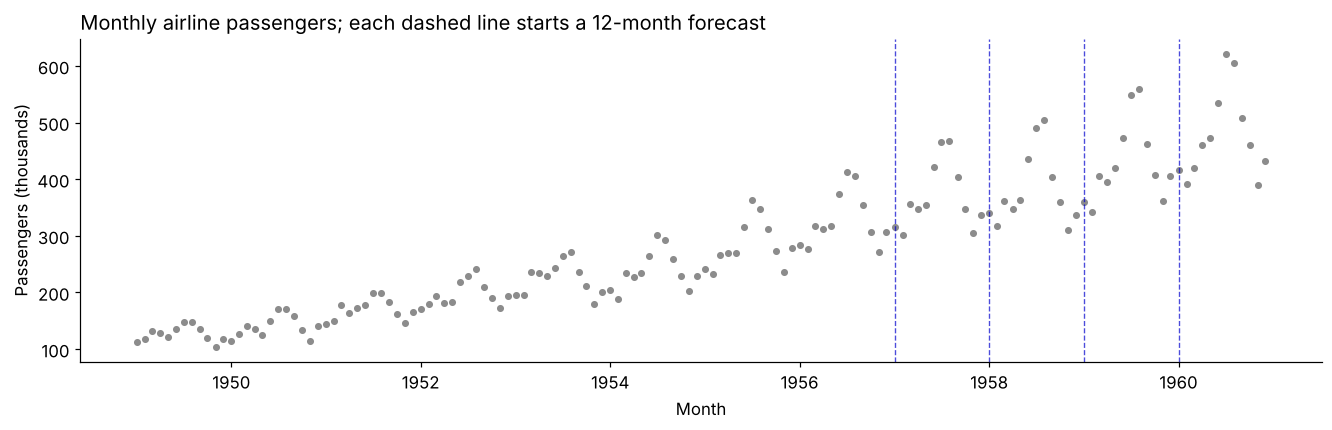

In [3]:
origin_lengths = (96, 108, 120, 132)  # the history ends in December 1956, 1957, 1958 and 1959
horizon = 12
fig, ax = plt.subplots(figsize=(12, 3.8), layout='constrained')
ax.scatter(series.index.to_timestamp(), series['passengers'], color='0.55', s=13)
for n in origin_lengths:
    ax.axvline(series.index[n].to_timestamp(), color='#0000CC', linestyle='--', linewidth=0.9, alpha=0.7)
ax.set(title='Monthly airline passengers; each dashed line starts a 12-month forecast',
       xlabel='Month', ylabel='Passengers (thousands)')
plt.show()

Traffic grows every year, and the summer peak grows with it.

## Hide the future, four times

Each dashed line is a **forecast origin**. The model gets the history before it and must forecast the next 12 months, which stay hidden until scoring. We do this at the end of 1956, 1957, 1958 and 1959, so each origin has one more year of history than the one before. There is no answer key, so each case's `reference` is `None`: TimeGym can only compare forecasts with what actually happened.

In [4]:
cases = []
for n in origin_lengths:
    history, hidden = series.iloc[:n].copy(), series.iloc[n:n + horizon].copy()
    cases.append(Case(task=ForecastTask(context=history, future_index=hidden.index.copy()),
                      observed=hidden, reference=None,  # real data: no answer key
                      manifest={'kind': 'AirPassengers', 'seed': None,
                                'origin': str(history.index[-1]), 'context_length': n,
                                'horizon': horizon, 'target_names': ['passengers'],
                                'source_sha256': source_sha256}))
display(pd.DataFrame([{'history ends': str(c.task.context.index[-1]),
                       'months of history': len(c.task.context),
                       'months to forecast': f'{c.task.future_index[0]} to {c.task.future_index[-1]}'}
                      for c in cases]))

,history ends,months of history,months to forecast
0,1956-12,96,1957-01 to 1957-12
1,1957-12,108,1958-01 to 1958-12
2,1958-12,120,1959-01 to 1959-12
3,1959-12,132,1960-01 to 1960-12


## Three simple forecasts

- **Historical mean**: the average of all the history.
- **Same month last year** (seasonal naive): repeat the last 12 months.
- **Ridge**: a linear regression that predicts each month from the 12 months before it, after rescaling them to mean 0 and spread 1. It forecasts the year step by step, feeding its own predictions back in. Its penalty (`alpha=1.0`) is fixed, not tuned.

We score each forecast by its mean absolute error (MAE), in thousands of passengers. Because traffic grows, a miss of 20 thousand means less in 1960 than in 1957, so we also report MASE(12): the MAE divided by the average miss of "same month last year" within that origin's history. Below 1, the forecast beat that rule's usual miss.

In [5]:
window = 12
scaler_template, ridge_template = StandardScaler(), Ridge(alpha=1.0)
models = {'Historical mean': Pipeline(NaiveForecaster(strategy='mean')),
          'Same month last year': Pipeline(NaiveForecaster(strategy='seasonal', period=12)),
          'Ridge': Pipeline(window_length=window).add(scaler_template).add(ridge_template)}
forecasts, results, rows = {}, {}, []
for i, case in enumerate(cases):
    for name, model in models.items():
        forecast = model.predict(case.task.context, case.task.future_index)  # history and dates only
        result = evaluate_forecast(case, forecast)
        result.manifest['model'] = name
        forecasts[i, name], results[i, name] = forecast, result
        rows.append({'history ends': str(case.task.context.index[-1]), 'model': name,
                     'MAE': result.metrics['mae'],
                     'MASE(12)': mase(case.observed.to_numpy(), forecast.point,
                                      case.task.context.to_numpy(), seasonality=12)})
assert all('mean_reference_mse' not in r.metrics for r in results.values())  # no answer key, no score against it
scores = pd.DataFrame(rows).pivot(index='history ends', columns='model').reindex(columns=list(models), level=1)
display(scores.round(2))

MAE                                    MASE(12)  \
model        Historical mean Same month last year  Ridge Historical mean   
history ends                                                               
1956-12               154.71                40.17  10.30            5.30   
1957-12               150.10                12.58  36.42            4.91   
1958-12               182.43                47.33  16.92            6.38   
1959-12               213.67                47.83  14.37            7.02   

                                         
model        Same month last year Ridge  
history ends                             
1956-12                      1.38  0.35  
1957-12                      0.41  1.19  
1958-12                      1.66  0.59  
1959-12                      1.57  0.47

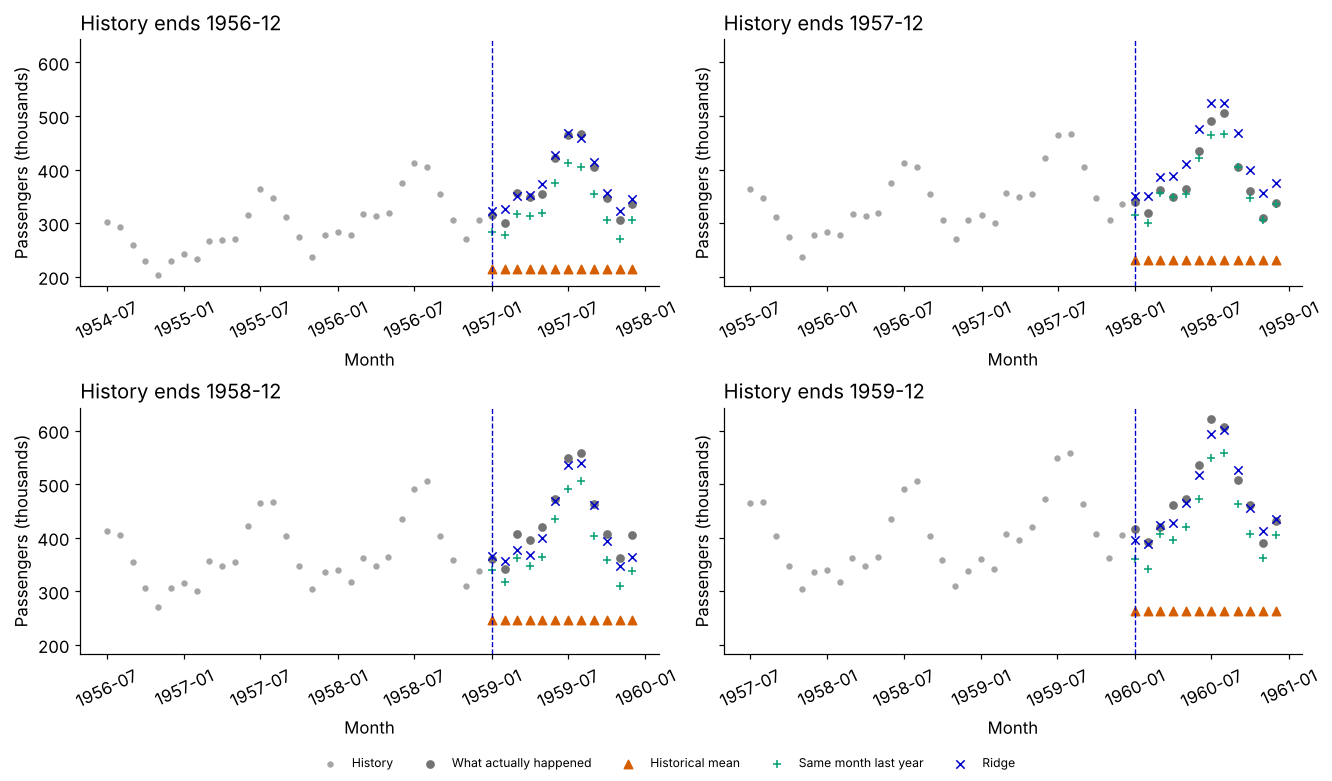

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True, layout='constrained')
colors = {'Historical mean': '#D55E00', 'Same month last year': '#009E73', 'Ridge': '#0000CC'}
markers = {'Historical mean': '^', 'Same month last year': '+', 'Ridge': 'x'}
for i, (ax, case) in enumerate(zip(axes.flat, cases)):
    recent = case.task.context.iloc[-30:]
    ax.scatter(recent.index.to_timestamp(), recent.iloc[:, 0], color='0.65', s=10, label='History')
    ax.scatter(case.observed.index.to_timestamp(), case.observed.iloc[:, 0],
               color='0.45', s=22, label='What actually happened')
    for name in models:
        ax.scatter(forecasts[i, name].index.to_timestamp(), forecasts[i, name].point[:, 0],
                   marker=markers[name], s=30, color=colors[name], linewidths=1, label=name)
    ax.axvline(case.task.future_index[0].to_timestamp(), color='#0000CC', linestyle='--', linewidth=0.9)
    ax.set(title=f'History ends {case.task.context.index[-1]}', xlabel='Month', ylabel='Passengers (thousands)')
    ax.tick_params(axis='x', labelrotation=25)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='outside lower center', ncol=5, fontsize=8)
plt.show()

Ridge has the smallest error at three of the four origins, with MASE(12) between 0.35 and 0.59 there. The exception is 1958: traffic grew only 3% that year, against about 12% in the years before and after, so repeating 1957 came close while Ridge expected the usual growth and overshot. The historical mean sits far below every year it forecasts, because it averages in the small early years.

Pooling all 48 forecast months shows each model's habits. Points below the diagonal are forecasts that came in too low.

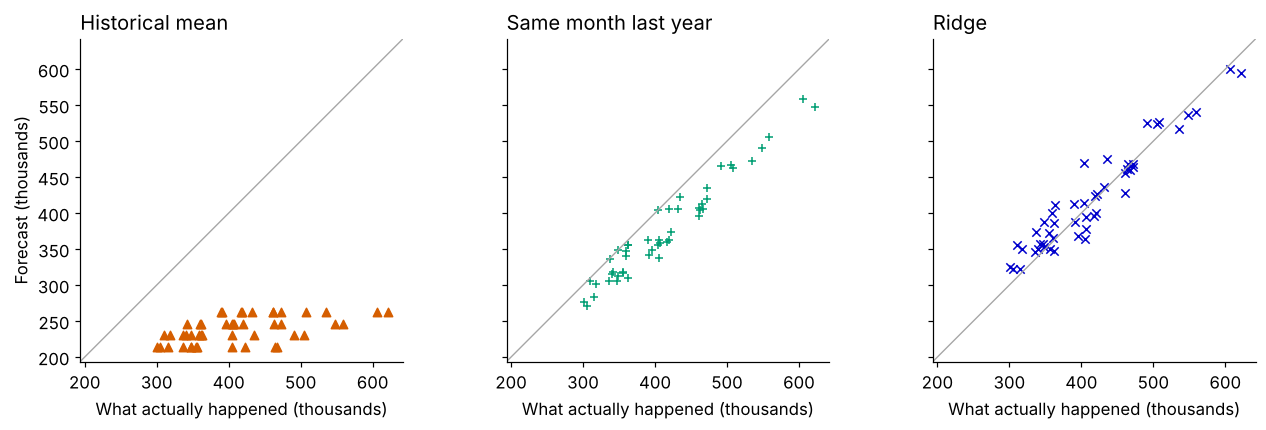

In [7]:
actual = np.concatenate([case.observed.iloc[:, 0].to_numpy() for case in cases])
predicted = {name: np.concatenate([forecasts[i, name].point[:, 0] for i in range(len(cases))])
             for name in models}
everything = np.concatenate([actual, *predicted.values()])
limits = (everything.min() - 20, everything.max() + 20)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True, layout='constrained')
for ax, name in zip(axes, models):
    ax.plot(limits, limits, color='0.65', linewidth=0.9)
    ax.scatter(actual, predicted[name], marker=markers[name], s=30, color=colors[name], linewidths=1)
    ax.set(title=name, xlabel='What actually happened (thousands)', xlim=limits, ylim=limits, aspect='equal')
axes[0].set_ylabel('Forecast (thousands)')
plt.show()

The historical mean is a flat band far below the diagonal: it can't follow the summer peaks. "Same month last year" follows the cycle but sits below the line almost everywhere, because it repeats last year and every year was busier than the one before. Ridge's points scatter around the line.

## Did Ridge see the future?

A model that wins this clearly deserves suspicion. The classic leak hides in the rescaling step: fit the scaler on the whole series, and the higher traffic of the months being forecast quietly shapes the inputs. In TimeGym the model is only ever handed the history and the dates to forecast, and the pipeline fits fresh copies of the scaler and Ridge at each origin. We check that at the last origin, where the history ends in December 1959.

Ridge learns from windows of 12 consecutive months, each paired with the month that follows. These pairs (lag rows) are all the scaler should ever see. Here are the first two and the last two:

In [8]:
last_history = cases[-1].task.context
values, months = last_history['passengers'].to_numpy(), last_history.index
lag_rows = np.asarray([values[t - window:t] for t in range(window, len(values))])
lag_table = pd.DataFrame({'window starts': months[:len(lag_rows)].astype(str),
                          'window ends': months[window - 1:-1].astype(str),
                          'month predicted': months[window:].astype(str),
                          'value predicted': values[window:]})
display(pd.concat([lag_table.head(2), lag_table.tail(2)]))

,window starts,window ends,month predicted,value predicted
0,1949-01,1949-12,1950-01,115.0
1,1949-02,1950-01,1950-02,126.0
118,1958-11,1959-10,1959-11,362.0
119,1958-12,1959-11,1959-12,405.0


The last pair predicts December 1959, the final month of history. Now we fit the same two steps by hand and look inside the fitted scaler.

In [9]:
inspected = SklearnForecaster([scaler_template, ridge_template], window_length=window).fit(last_history)
fitted_scaler = inspected.models_[0].named_steps['step_0']
display(pd.Series({'months of history': len(last_history),
                   'lag rows in that history': len(lag_rows),
                   'rows the scaler saw': int(fitted_scaler.n_samples_seen_),
                   'scaler averages equal those rows\' averages': bool(np.allclose(fitted_scaler.mean_,
                                                                                    lag_rows.mean(axis=0))),
                   'scaler we passed in was fitted': hasattr(scaler_template, 'mean_')},
                  name='last origin').to_frame())

assert fitted_scaler.n_samples_seen_ == len(lag_rows)  # the scaler saw the history's lag rows...
np.testing.assert_allclose(fitted_scaler.mean_, lag_rows.mean(axis=0))  # ...and nothing else
assert not hasattr(scaler_template, 'mean_') and not hasattr(ridge_template, 'coef_')  # fresh copies each origin
np.testing.assert_allclose(inspected.predict(cases[-1].task.future_index).point,
                           forecasts[len(cases) - 1, 'Ridge'].point)  # the model behind the forecast above

,last origin
months of history,132
lag rows in that history,120
rows the scaler saw,120
scaler averages equal those rows' averages,True
scaler we passed in was fitted,False


The scaler saw exactly the 120 lag rows of the history, and its averages are their averages: nothing from 1960 got in. The scaler and Ridge we passed in were never fitted themselves, so nothing learned at one origin carries over to the next. And the model we inspected gives exactly the forecast scored above. Ridge's win is not a leak.

## Put an uncertainty band around one forecast

A point forecast doesn't say how sure it is. At the last origin we fit a mean-reversion model (`GaussianAR1Forecaster`), which returns 256 possible paths for 1960 and an 80% band for each month: a band for each month on its own, not a band the whole year stays inside 80% of the time. The model knows nothing about the yearly cycle, and we picked it to see what that looks like.

In [10]:
last_case = cases[-1]
band_model = Pipeline(GaussianAR1Forecaster(n_samples=256, seed=17))
band_forecast = band_model.predict(last_case.task.context, last_case.task.future_index)
band_result = evaluate_forecast(last_case, band_forecast, check_dependence=True)
band_result.manifest['model'] = 'GaussianAR1Forecaster'

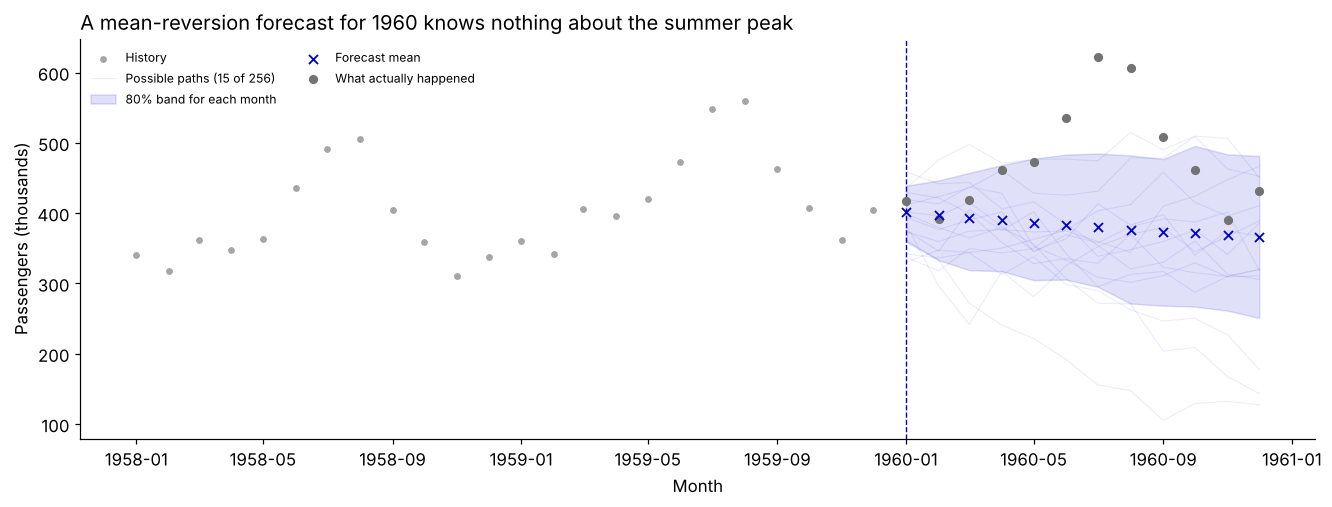

In [11]:
dates = band_forecast.index.to_timestamp()
recent = last_case.task.context.iloc[-24:]
fig, ax = plt.subplots(figsize=(12, 4.5), layout='constrained')
ax.scatter(recent.index.to_timestamp(), recent.iloc[:, 0], color='0.65', s=12, label='History')
for k, path in enumerate(band_forecast.samples[:15, :, 0]):
    ax.plot(dates, path, color='#0000CC', alpha=0.08, linewidth=0.7,
            label='Possible paths (15 of 256)' if k == 0 else None)
ax.fill_between(dates, band_forecast.quantiles[:, 0, 0], band_forecast.quantiles[:, 0, -1],
                color='#0000CC', alpha=0.12, label='80% band for each month')
ax.scatter(dates, band_forecast.point[:, 0], color='#0000CC', marker='x', s=35,
           linewidths=1.2, label='Forecast mean', zorder=4)
ax.scatter(last_case.observed.index.to_timestamp(), last_case.observed.iloc[:, 0],
           color='0.45', s=25, label='What actually happened', zorder=3)
ax.axvline(dates[0], color='#0000CC', linestyle='--', linewidth=0.9)
ax.set(title='A mean-reversion forecast for 1960 knows nothing about the summer peak',
       xlabel='Month', ylabel='Passengers (thousands)')
ax.legend(fontsize=8, ncol=2)
plt.show()

The forecast drifts slowly downward, as mean reversion predicts, while the real 1960 climbs to its summer peak. June to September land above the band. TimeGym scores the band against what actually happened:

In [12]:
observed = last_case.observed.iloc[:, 0].to_numpy()
inside = (observed >= band_forecast.quantiles[:, 0, 0]) & (observed <= band_forecast.quantiles[:, 0, -1])
outside = ', '.join(str(month) for month, ok in zip(last_case.observed.index, inside) if not ok)
print(f'{inside.sum()} of {inside.size} months inside the 80% band; outside: {outside}.')
print(f"Average miss of the forecast mean: {band_result.metrics['mae']:.0f} thousand passengers "
      f"(same month last year: {results[len(cases) - 1, 'Same month last year'].metrics['mae']:.0f}).")
display(pd.DataFrame([{'check': d.name, 'status': d.status, 'what it says': d.message}
                      for d in band_result.diagnostics
                      if d.name in {'interval_coverage', 'sample_scores', 'reference_covariance'}]))

8 of 12 months inside the 80% band; outside: 1960-06, 1960-07, 1960-08, 1960-09.
Average miss of the forecast mean: 95 thousand passengers (same month last year: 48).


,check,status,what it says
0,interval_coverage,INCONCLUSIVE,One-path coverage across possibly dependent coordinates does not establish calibration.
1,sample_scores,INCONCLUSIVE,Empirical marginal and joint scores are descriptive; no capability acceptance tolerance was declared.
2,reference_covariance,UNSUPPORTED,Predictive samples and a reference covariance are required.


Eight of the 12 months fell inside the 80% band, and the forecast mean missed by about twice as much as "same month last year". TimeGym marks the coverage INCONCLUSIVE: scored, but with no pass mark, because 12 neighboring months of one year are too few, and too alike, to judge an 80% band. The path scores (`sample_scores`) are INCONCLUSIVE too, since no pass mark was set and TimeGym won't invent one. The covariance check is UNSUPPORTED (not checked): it needs an answer key, and real data has none. The plot says what the scores can't: a band is only as good as the model under it.

## Keep the evidence

A real-data study can't be regenerated from a seed. What you can keep is a report of every score and check, with the data's checksum, the origins and the model settings. Its output checks (right dates, right shape, finite values, quantiles in order) confirm that no forecast here was broken. TimeGym can't replay this study from the report alone, since Ridge comes from scikit-learn and the data from a file, so keep the CSV and this notebook with it.

In [13]:
real_report = TestReport(cases=[*results.values(), band_result], metadata={
    'dataset': 'AirPassengers', 'source_sha256': source_sha256,
    'origin_lengths': list(origin_lengths), 'horizon': horizon,
    'point_models': {'mean': {}, 'seasonal_naive': {'period': 12},
                     'ridge': {'window_length': window, 'alpha': 1.0}},
    'band_model': {'model': 'GaussianAR1Forecaster', 'n_samples': 256, 'seed': 17},
    'automatic_replay_supported': False,
    'reproduction': 'Run this notebook against the checked-in CSV with matching dependencies.',
    'interpretation': 'Four ordered windows from one series, not independent datasets.',
})
summary = real_report.summary
passed = sum(d.name == 'forecast_contract' and d.status == 'PASS' for r in real_report.cases for d in r.diagnostics)
print(f"{summary['cases']} results saved: {len(results)} point forecasts and 1 band, "
      f"{len(real_report.to_json().encode('utf-8')):,} bytes of JSON.")
print(f"Output checks passed: {passed} of {summary['cases']}. All statuses: "
      + ', '.join(f'{status} {count}' for status, count in summary['status_counts'].items()) + '.')
assert summary['failed_cases'] == 0  # no forecast was broken

13 results saved: 12 point forecasts and 1 band, 24,696 bytes of JSON.
Output checks passed: 13 of 13. All statuses: PASS 13, FAIL 0, INCONCLUSIVE 16, UNSUPPORTED 25, ERROR 0.


## Change one thing

- Add a last-value forecast (`NaiveForecaster(strategy='last')`) at the same four origins.
- Pick a different Ridge window or penalty in advance, and judge it on origins you haven't looked at yet.
- Try your own monthly series: keep its units, split it in time order, and let the pipeline fit any rescaling on the history only.

**What this doesn't show.** Four origins from one series are four looks at one history, not four independent tests, so they can't rank these models in general. Comparing many settings on these same origins would quietly turn them into a tuning set; keep fresh origins for the final comparison. The AR(1) band also ignores the uncertainty in the model's own estimates.

**Next:** [Univariate uncertainty](08_univariate_uncertainty.ipynb).